# Building makemore Part 3: Activations, Gradients & Batch Normalization

This notebook investigates the deep mechanics of training neural networks:
1. **The Pathologies of Bad/Unscaled Initialization:** Exploding initial loss, saturated non-linearities, and dead neurons.
2. **Kaiming / He Initialization:** Fixing the starting point by scaling weights to preserve activation variance.
3. **The Limitation of Kaiming Init:** Activation drift (internal covariate shift) during extended training.
4. **Batch Normalization (BatchNorm) from Scratch:** Structurally stabilizing the hidden representation across all layers and training steps.


## 1. Setup & Dataset Preparation
Loading the names dataset, constructing character vocabulary mappings (`stoi`, `itos`), and generating train (80%), dev (10%), and test (10%) splits with a context length of `block_size = 4`.

In [1]:
import torch
import random
from pathlib import Path

import matplotlib.pyplot as plt
import torch.nn.functional as F

In [2]:
DATA_DIR = Path.cwd().parent / "data"
DATA_PATH = DATA_DIR / "names.txt"

words = DATA_PATH.read_text("utf-8").splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [3]:
# Build the vocabulary of characters and mappings to/from integer
chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}

In [4]:
block_size = 4

def build_dataset(words):
    X, y = [], []
    for w in words:
        context = [0] * block_size
        
        for ch in w + '.':
            X.append(context)
            iy = stoi[ch]
            y.append(iy)
            context = context[1:] + [iy]
    
    X = torch.tensor(X)
    y = torch.tensor(y)
    return X, y

In [5]:
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, ytr = build_dataset(words[:n1])
Xdev, ydev = build_dataset(words[n1:n2])
Xte, yte = build_dataset(words[n2:])

## 2. Pathologies of Unscaled / Bad Weight Initialization

We begin by initializing our Multilayer Perceptron (MLP) weights with standard Gaussian noise ($\mathcal{N}(0, 1)$) without scaling ($W_1 \sim \text{randn}, W_2 \sim \text{randn}$).


### 2.1 Step 0 Inspection: Initial Loss & Activation Distributions
We run a single forward pass (`break` after step 0) to inspect the network's health at the starting line.


In [6]:
emb_dim = 10
vocab_size = 27
hidden_size = 300

C = torch.randn(vocab_size, emb_dim)

W1 = torch.randn(hidden_size, block_size * emb_dim)
b1 = torch.zeros(hidden_size)
W2 = torch.randn((vocab_size, hidden_size), )
b2 = torch.zeros(vocab_size)

params = [C, W1, W2, b1, b2]

for p in params:
    p.requires_grad = True

In [7]:
epochs = 100000
batch_size = 128
N = len(Xtr)
lossi = []

for i in range(epochs):
    # Batching
    ix = torch.randint(0, N, (batch_size, ))
    x_b = Xtr[ix]
    y_b = ytr[ix]

    # Forward pass
    X_emb = C[x_b].reshape(-1, emb_dim * block_size)
    h_preact = X_emb @ W1.T + b1
    h = torch.tanh(h_preact)
    logits = h @ W2.T + b2
    loss = F.cross_entropy(logits, y_b)

    # Backward pass
    for p in params:
        p.grad = None
    loss.backward()
    lossi.append(loss.item())

    # Gradient Descent
    lr = 0.1 if i < 60000 else 0.01
    for p in params:
            p.data -= lr * p.grad

    if i % 1000 == 0:
         print(f"Step: {i} Loss: {loss.item():.4f}")
    
    break # Testing the initialization state


Step: 0 Loss: 33.1602


#### Problem 1: Exploding Initial Loss (The "Hockey Stick")

Because the output layer $W_2$ is unscaled, initial logits are large, random, and erratic. The model confidently predicts wrong characters at step 0, causing cross-entropy loss to explode far beyond the expected uniform baseline of $-\log(1/27) \approx 3.30$.


tensor(43.1962, grad_fn=<VarBackward0>)


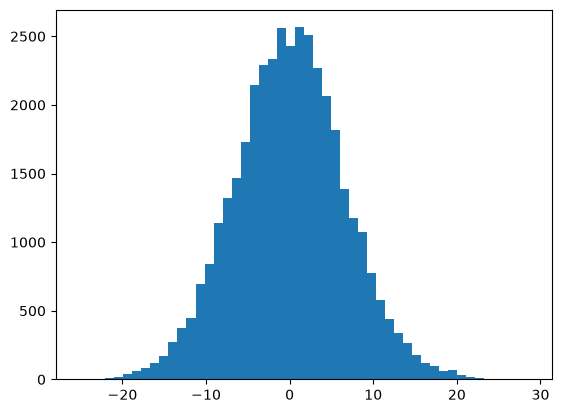

In [8]:
# Distribution of pre-activations
plt.hist(h_preact.view(-1).tolist(), bins=50);
print(h_preact.var())

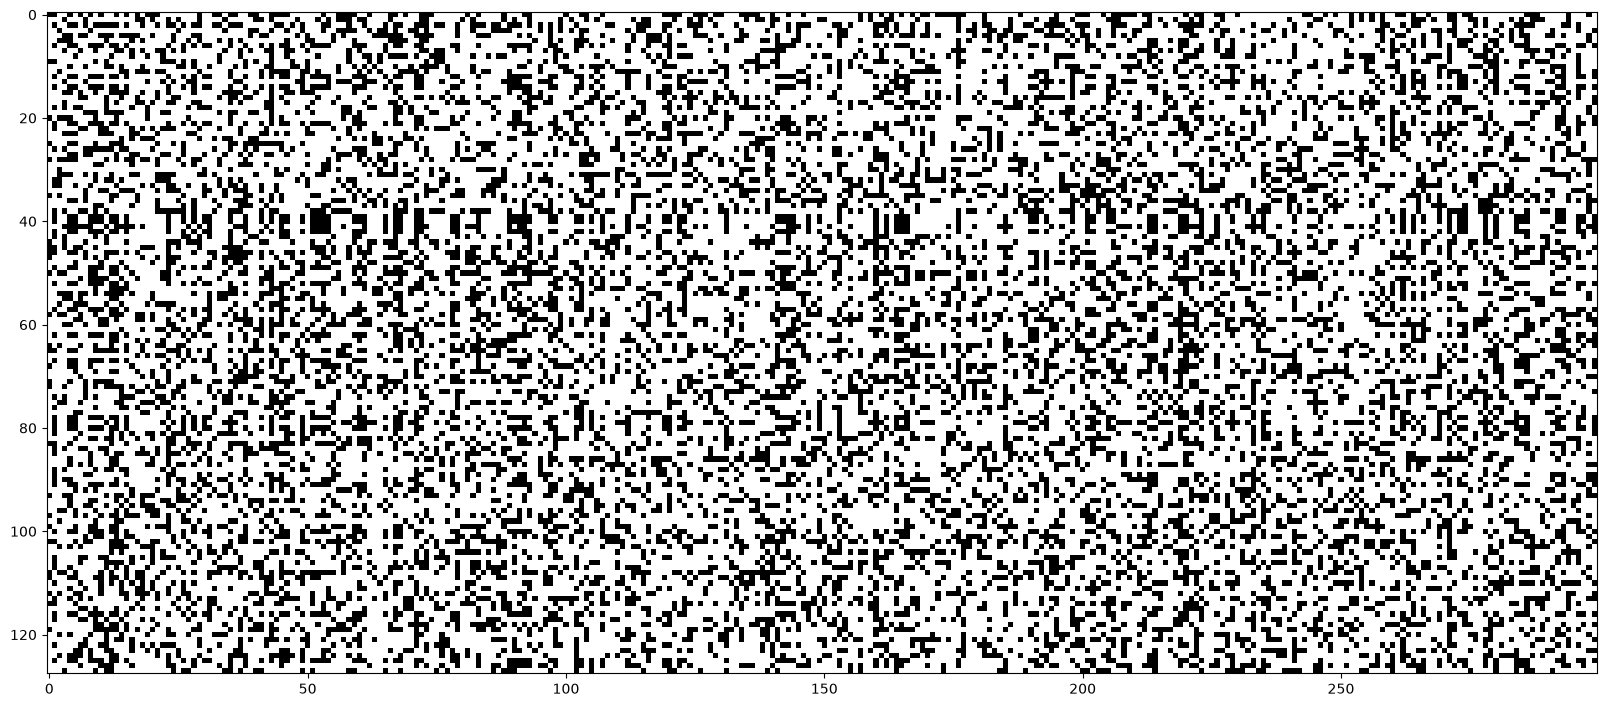

In [9]:
plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap='grey', interpolation='nearest')

tensor(0.8795, grad_fn=<VarBackward0>)


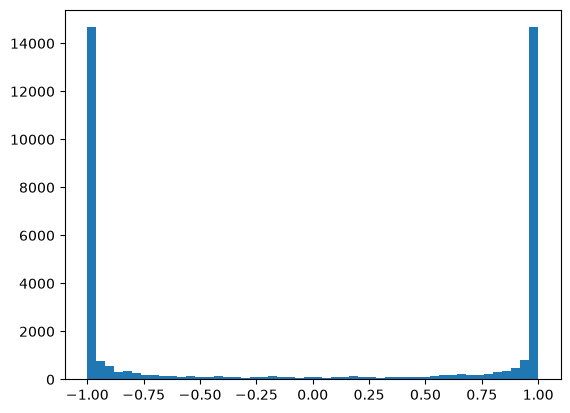

In [10]:
# Distribution of tanh
plt.hist(h.view(-1).tolist(), bins=50);
print(h.var())

#### Problem 2: Activation Saturation, Dead Neurons & Crippled Learning

As shown in the diagnostic plots above:
- **Pre-activations ($h_{\text{preact}}$):** Range from $[-25, +25]$ (variance $\approx 40$) because $W_1$ is unscaled ($\sigma = \sqrt{\text{fan\_in}} = \sqrt{40} \approx 6.32$).
- **$\tanh$ Saturation:** More than $80\%$ of activations are shoved into the flat tails ($|h| > 0.99$).
- **Dead Neurons:** In the 2D density map, solid white columns represent neurons saturated across *all* 128 examples in the batch. Their local gradient $(1 - \tanh^2) \approx 0$, effectively killing their learning signal and crippling the effective batch size.


### 2.2 Training Dynamics with Unscaled Weights (100,000 Steps)
Let's train this unscaled model for 100,000 steps to see if gradient descent can escape the saturation trap on its own.


In [11]:
emb_dim = 10
vocab_size = 27
hidden_size = 300

C = torch.randn(vocab_size, emb_dim)

W1 = torch.randn(hidden_size, block_size * emb_dim)
b1 = torch.zeros(hidden_size)
W2 = torch.randn((vocab_size, hidden_size), )
b2 = torch.zeros(vocab_size)

params = [C, W1, W2, b1, b2]

for p in params:
    p.requires_grad = True

In [12]:
epochs = 100000
batch_size = 128
N = len(Xtr)
lossi = []

for i in range(epochs):
    # Batching
    ix = torch.randint(0, N, (batch_size, ))
    x_b = Xtr[ix]
    y_b = ytr[ix]

    # Forward pass
    X_emb = C[x_b].reshape(-1, emb_dim * block_size)
    h_preact = X_emb @ W1.T + b1
    h = torch.tanh(h_preact)
    logits = h @ W2.T + b2
    loss = F.cross_entropy(logits, y_b)

    # Backward pass
    for p in params:
        p.grad = None
    loss.backward()
    lossi.append(loss.item())

    # Gradient Descent
    lr = 0.1 if i < 60000 else 0.01
    for p in params:
            p.data -= lr * p.grad

    if i % 1000 == 0:
         print(f"Step: {i} Loss: {loss.item():.4f}")


Step: 0 Loss: 35.8553
Step: 1000 Loss: 3.6972
Step: 2000 Loss: 2.5984
Step: 3000 Loss: 2.7488
Step: 4000 Loss: 3.1276
Step: 5000 Loss: 2.6703
Step: 6000 Loss: 2.4285
Step: 7000 Loss: 2.7546
Step: 8000 Loss: 2.4889
Step: 9000 Loss: 2.6874
Step: 10000 Loss: 2.5591
Step: 11000 Loss: 2.2691
Step: 12000 Loss: 2.3741
Step: 13000 Loss: 2.4331
Step: 14000 Loss: 2.2813
Step: 15000 Loss: 2.4158
Step: 16000 Loss: 2.3218
Step: 17000 Loss: 2.3517
Step: 18000 Loss: 2.5192
Step: 19000 Loss: 2.3787
Step: 20000 Loss: 2.4113
Step: 21000 Loss: 2.2779
Step: 22000 Loss: 2.1278
Step: 23000 Loss: 2.4331
Step: 24000 Loss: 2.3840
Step: 25000 Loss: 2.5388
Step: 26000 Loss: 2.3210
Step: 27000 Loss: 2.3566
Step: 28000 Loss: 2.2501
Step: 29000 Loss: 2.2359
Step: 30000 Loss: 2.4535
Step: 31000 Loss: 2.2044
Step: 32000 Loss: 2.2362
Step: 33000 Loss: 2.2835
Step: 34000 Loss: 2.1204
Step: 35000 Loss: 2.0776
Step: 36000 Loss: 2.1398
Step: 37000 Loss: 2.2403
Step: 38000 Loss: 2.4659
Step: 39000 Loss: 2.3799
Step: 40000 

tensor(5.2743, grad_fn=<StdBackward0>)


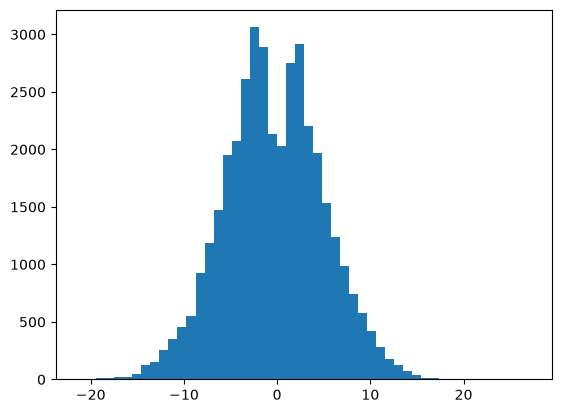

In [13]:
# Distribution of pre-activations
plt.hist(h_preact.view(-1).tolist(), bins=50);
print(h_preact.std())

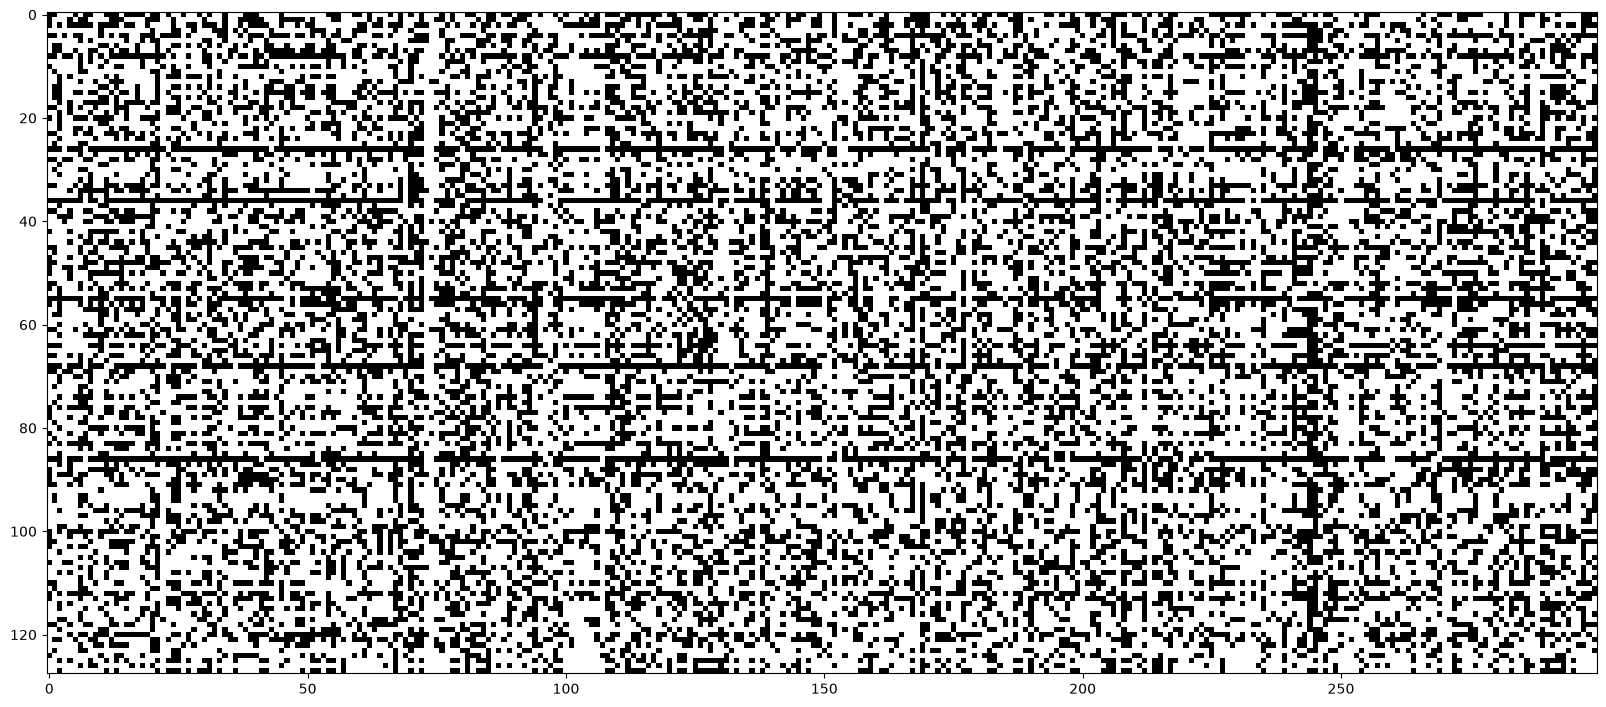

In [14]:
plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap='grey', interpolation='nearest')

tensor(0.8765, grad_fn=<VarBackward0>)


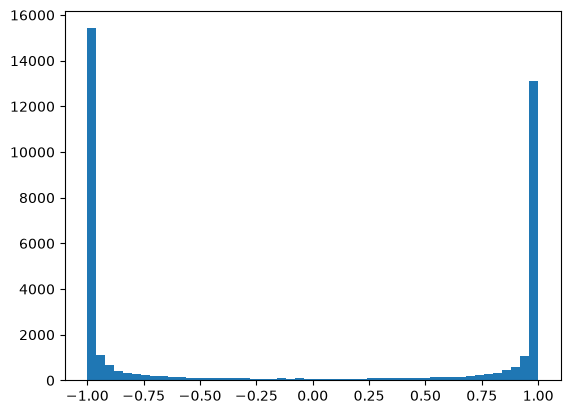

In [15]:
# Distribution of tanh
plt.hist(h.view(-1).tolist(), bins=50);
print(h.var())

#### Post-Training Observations (Unscaled Model)
Notice how training made the problem even worse:
- The pre-activations became **bimodal** (two horns at $\approx \pm 3$ and a valley at 0).
- Over $85\%$ of the $\tanh$ activations are clamped to $-1.0$ or $+1.0$ (twin spires of $\sim 16,000$).
- Dozens of neurons are permanently frozen as dead columns. The network is trapped in saturation!


## 3. Fixing the Starting Point: Scaled Weights (Kaiming / He Initialization)

To fix the pathologies observed in Section 2:
1. **Output Layer ($W_2, b_2$):** Scale $W_2 \times 0.01$ and $b_2 = 0$. Logits start near zero, yielding uniform probabilities and an optimal starting loss of $-\log(1/27) \approx 3.30$.
2. **Hidden Layer ($W_1$):** Scale $W_1 \times \frac{1}{\sqrt{\text{fan\_in}}}$ (Kaiming initialization). This ensures the variance of $h_{\text{preact}}$ remains $\approx 1.0$ (range $[-3, +3]$), keeping $\tanh$ in its active linear region.


### 3.1 Step 0 Inspection with Scaled Weights
Evaluating a single forward pass to confirm that the initial loss is optimal and dead neurons are eliminated.


In [16]:
emb_dim = 10
vocab_size = 27
hidden_size = 300

C = torch.randn(vocab_size, emb_dim)

W1 = torch.randn(hidden_size, block_size * emb_dim) * ((block_size * emb_dim) ** -0.5)
b1 = torch.zeros(hidden_size)
W2 = torch.randn((vocab_size, hidden_size), ) * 0.01 # Because here want the logits to have similar values
b2 = torch.zeros(vocab_size)

params = [C, W1, W2, b1, b2]

for p in params:
    p.requires_grad = True

In [17]:
epochs = 100000
batch_size = 128
N = len(Xtr)
lossi = []

for i in range(epochs):
    # Batching
    ix = torch.randint(0, N, (batch_size, ))
    x_b = Xtr[ix]
    y_b = ytr[ix]

    # Forward pass
    X_emb = C[x_b].reshape(-1, emb_dim * block_size)
    h_preact = X_emb @ W1.T + b1
    h = torch.tanh(h_preact)
    logits = h @ W2.T + b2
    loss = F.cross_entropy(logits, y_b)

    # Backward pass
    for p in params:
        p.grad = None
    loss.backward()
    lossi.append(loss.item())

    # Gradient Descent
    lr = 0.1 if i < 60000 else 0.01
    for p in params:
            p.data -= lr * p.grad

    if i % 1000 == 0:
         print(f"Step: {i} Loss: {loss.item():.4f}")

    break

Step: 0 Loss: 3.3140


tensor(0.9924, grad_fn=<VarBackward0>)


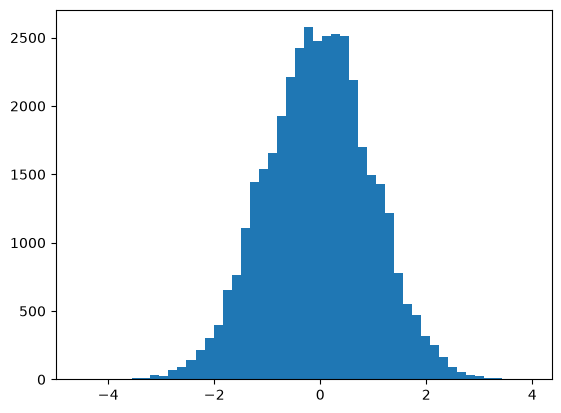

In [18]:
# Distribution of pre-activations
plt.hist(h_preact.view(-1).tolist(), bins=50);
print(h_preact.var())

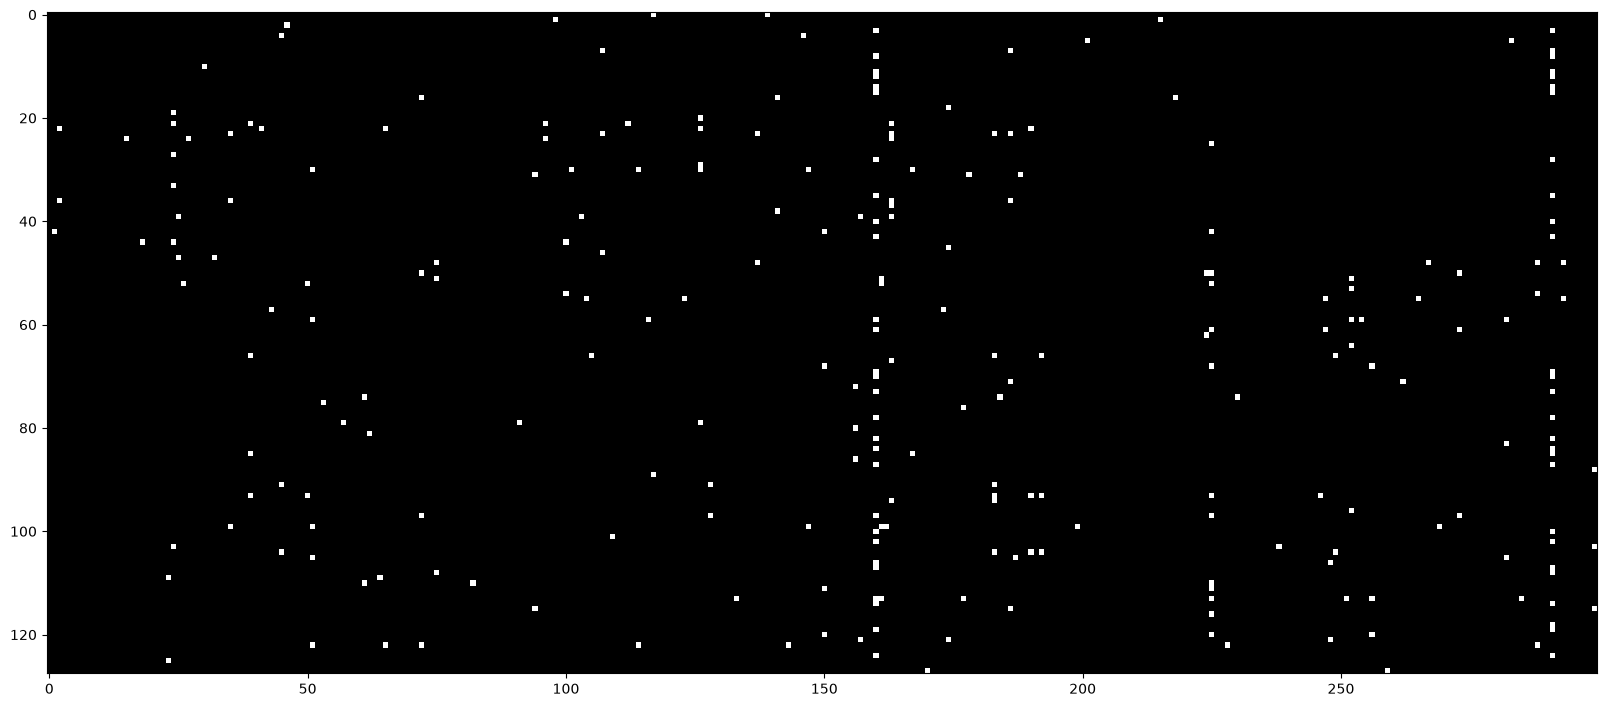

In [19]:
plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap='grey', interpolation='nearest')

tensor(0.3955, grad_fn=<VarBackward0>)


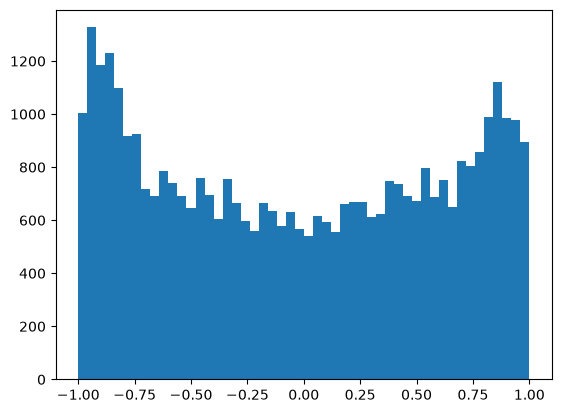

In [20]:
# Distribution of tanh
plt.hist(h.view(-1).tolist(), bins=50);
print(h.var())

### 3.2 Training Dynamics with Scaled Weights (100,000 Steps)
Now we train the scaled model for 100,000 steps. While step 0 is healthy, observe what happens to activations over extended training.


In [21]:
emb_dim = 10
vocab_size = 27
hidden_size = 300

C = torch.randn(vocab_size, emb_dim)

W1 = torch.randn(hidden_size, block_size * emb_dim) * ((block_size * emb_dim) ** -0.5)
b1 = torch.zeros(hidden_size)
W2 = torch.randn((vocab_size, hidden_size), ) * 0.01 # Because here want the logits to have similar values
b2 = torch.zeros(vocab_size)

params = [C, W1, W2, b1, b2]

for p in params:
    p.requires_grad = True

In [22]:
epochs = 100000
batch_size = 128
N = len(Xtr)
lossi = []

for i in range(epochs):
    # Batching
    ix = torch.randint(0, N, (batch_size, ))
    x_b = Xtr[ix]
    y_b = ytr[ix]

    # Forward pass
    X_emb = C[x_b].reshape(-1, emb_dim * block_size)
    h_preact = X_emb @ W1.T + b1
    h = torch.tanh(h_preact)
    logits = h @ W2.T + b2
    loss = F.cross_entropy(logits, y_b)

    # Backward pass
    for p in params:
        p.grad = None
    loss.backward()
    lossi.append(loss.item())

    # Gradient Descent
    lr = 0.1 if i < 60000 else 0.01
    for p in params:
            p.data -= lr * p.grad

    if i % 1000 == 0:
         print(f"Step: {i} Loss: {loss.item():.4f}")


Step: 0 Loss: 3.3068
Step: 1000 Loss: 2.2851
Step: 2000 Loss: 2.3484
Step: 3000 Loss: 2.2325
Step: 4000 Loss: 2.2148
Step: 5000 Loss: 2.2311
Step: 6000 Loss: 2.2590
Step: 7000 Loss: 1.9821
Step: 8000 Loss: 2.4031
Step: 9000 Loss: 2.1227
Step: 10000 Loss: 2.1776
Step: 11000 Loss: 2.1525
Step: 12000 Loss: 2.0121
Step: 13000 Loss: 1.9396
Step: 14000 Loss: 1.9829
Step: 15000 Loss: 2.1364
Step: 16000 Loss: 1.9491
Step: 17000 Loss: 2.0562
Step: 18000 Loss: 1.9197
Step: 19000 Loss: 2.1200
Step: 20000 Loss: 1.9456
Step: 21000 Loss: 2.0905
Step: 22000 Loss: 1.8476
Step: 23000 Loss: 1.9532
Step: 24000 Loss: 2.1847
Step: 25000 Loss: 1.9358
Step: 26000 Loss: 1.8760
Step: 27000 Loss: 1.8576
Step: 28000 Loss: 1.9180
Step: 29000 Loss: 1.7856
Step: 30000 Loss: 2.1628
Step: 31000 Loss: 2.0032
Step: 32000 Loss: 1.9274
Step: 33000 Loss: 1.9916
Step: 34000 Loss: 2.0367
Step: 35000 Loss: 1.8704
Step: 36000 Loss: 2.0064
Step: 37000 Loss: 1.8777
Step: 38000 Loss: 1.9526
Step: 39000 Loss: 1.7899
Step: 40000 L

tensor(7.8756, grad_fn=<VarBackward0>)


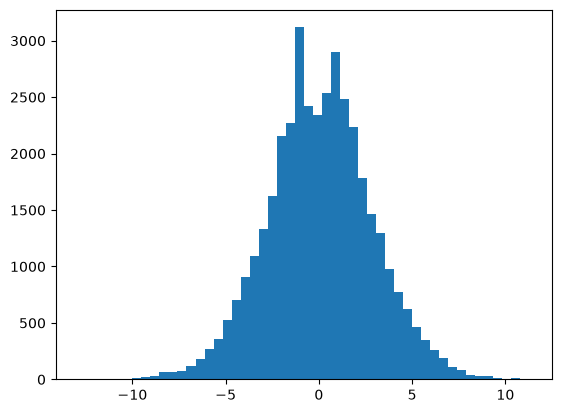

In [23]:
# Distribution of pre-activations
plt.hist(h_preact.view(-1).tolist(), bins=50);
print(h_preact.var())

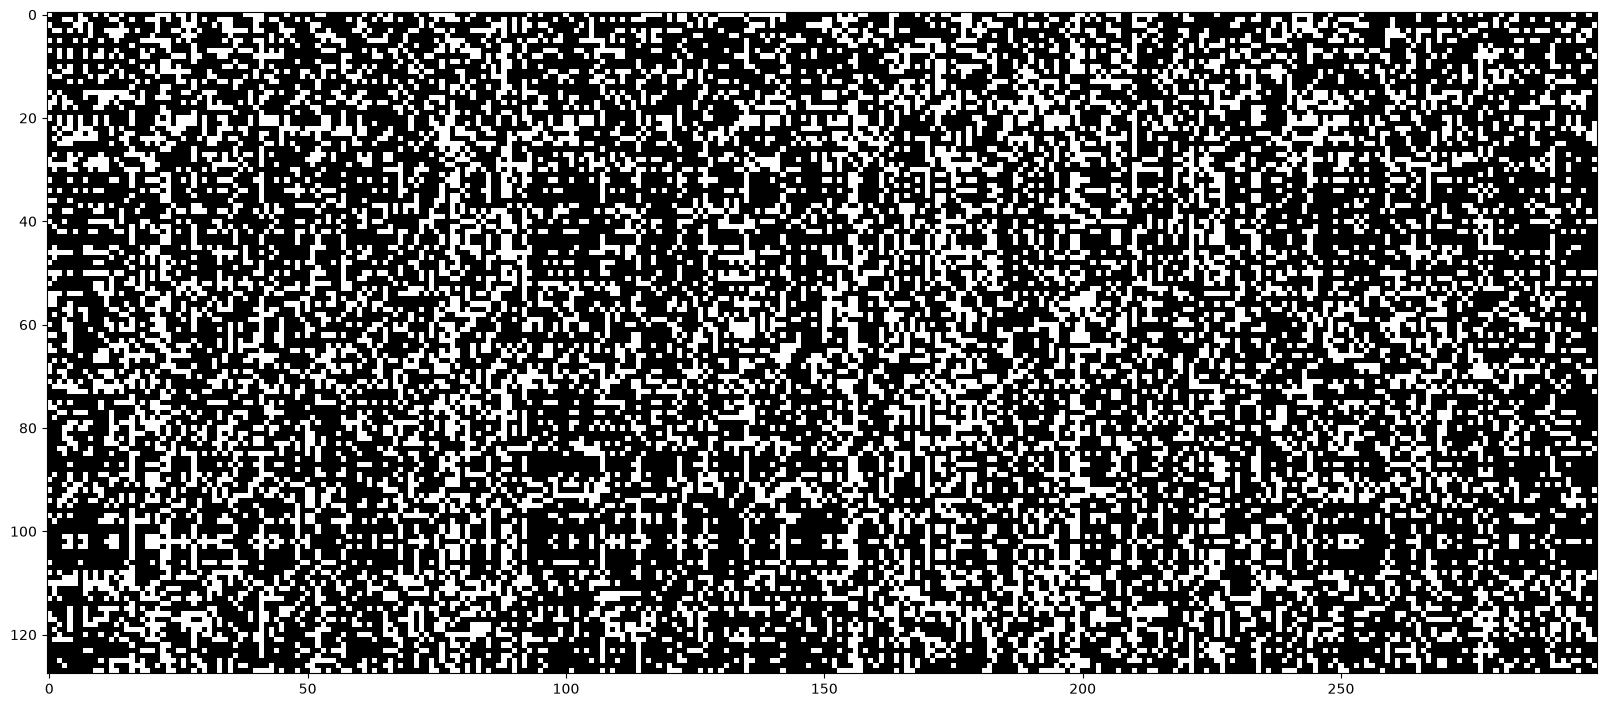

In [24]:
plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap='grey', interpolation='nearest')

tensor(0.7293, grad_fn=<VarBackward0>)


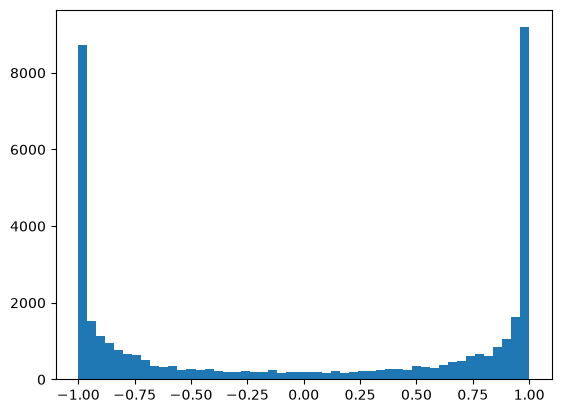

In [25]:
# Distribution of tanh
plt.hist(h.view(-1).tolist(), bins=50);
print(h.var())

#### The Limitation of Kaiming Init: Activation Drift (Internal Covariate Shift)

Comparing the plots before and after training reveals a key limitation:
- At Step 0, $h_{\text{preact}}$ was cleanly bounded within $[-3.5, +3.5]$.
- After 100,000 steps, as weights naturally grew during gradient descent, $h_{\text{preact}}$ drifted out to $[-10, +10]$.
- Partial saturation crept back in (spikes at $\pm 1$ rose to $\approx 9,000$).
- **Core Lesson:** Kaiming initialization only fixes the network at the starting line. It has no mechanism to keep activations in check as training evolves.


## 4. Batch Normalization (BatchNorm) from Scratch

Instead of hoping weights stay well-scaled throughout training, **Batch Normalization** directly standardizes hidden layer pre-activations at every forward pass:

$$\hat{h} = \frac{h_{\text{preact}} - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}, \quad h_{\text{norm}} = \gamma \hat{h} + \beta$$

- **Elimination of bias $b_1$:** Subtracting the batch mean $\mu_B$ completely cancels out any constant bias added before BatchNorm ($b_1$ is redundant).
- **Scale invariance:** Any constant multiplier $\alpha$ on $W_1$ divides out in the fraction ($\frac{\alpha h - \alpha \mu}{\alpha \sigma} = \frac{h - \mu}{\sigma}$). We no longer need to calculate precise Kaiming multipliers for $W_1$!
- **Learnable scale ($\gamma$ / `bngain`) and shift ($\beta$ / `bnbias`):** Allow each feature to independently customize its own distribution.
- **Running statistics (`bnmean_running`, `bnstd_running`):** Tracked as exponential moving averages during training, then frozen for deterministic inference (eval/test/sampling).


### 4.1 Step 0 Inspection with BatchNorm
Evaluating a single forward pass with BatchNorm enabled (`bngain = 1`, `bnbias = 0`) to confirm standard normal distributions before training.


In [26]:
emb_dim = 10
vocab_size = 27
hidden_size = 300


C = torch.randn(vocab_size, emb_dim)

W1 = torch.randn(hidden_size, block_size * emb_dim) # We don't need to scale W1 anymore
# b1 = torch.zeros(hidden_size) # We don't need b1 because we are using BatchNorm here (It would have just get cancelled)
W2 = torch.randn(vocab_size, hidden_size ) * 0.01 # Still helpul to prevent the initial hockey stick loss
b2 = torch.zeros(vocab_size)

bngain = torch.ones(1, hidden_size)
bnbias = torch.zeros(1, hidden_size)

params = [C, W1, W2, b2, bngain, bnbias]

bnmean_running = torch.zeros((1, hidden_size))
bnstd_running = torch.ones((1, hidden_size))

for p in params:
    p.requires_grad = True

In [27]:
steps = 100_000
batch_size = 128
N = len(Xtr)
lossi = []

for i in range(steps):
    # Batching
    ix = torch.randint(0, N, (batch_size,))
    X_b = Xtr[ix]
    y_b = ytr[ix]

    # Forward Pass
    X_emb = C[X_b].reshape(-1, emb_dim * block_size)
    h_preact = X_emb @ W1.T

    # BatchNorm
    bnmeani = h_preact.mean(dim=0, keepdim=True)
    bnstdi = h_preact.std(dim=0, keepdim=True)

    h_norm = bngain * ((h_preact - bnmeani) / bnstdi) + bnbias

    with torch.no_grad():
        bnmean_running = 0.99 * bnmean_running + 0.01 * bnmeani
        bnstd_running = 0.99 * bnstd_running + 0.01 * bnstdi

    h = torch.tanh(h_norm)
    logits = h @ W2.T + b2

    loss = F.cross_entropy(logits, y_b)

    # Backward pass
    for p in params:
        p.grad = None # Zero grad

    loss.backward()

    lr = 0.1 if i < 60_000 else 0.01

    for p in params:
        p.data += -lr * p.grad

    lossi.append(loss.item())

    if i % 1000 == 0:
        print(f"Loss: {loss.item()}")


    break


Loss: 3.3004989624023438


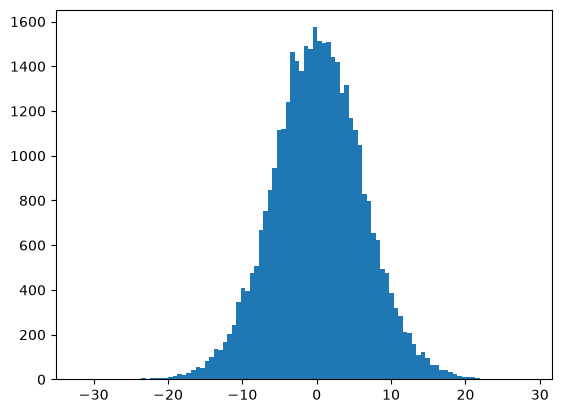

In [28]:
# Distribution of h_preact
plt.hist(h_preact.view(-1).tolist(), bins=100);

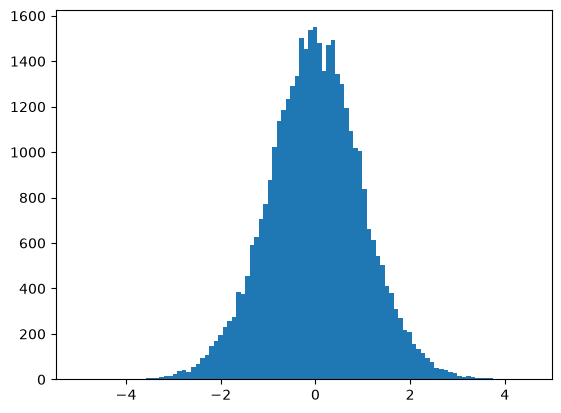

In [29]:
# After BatchNorm
plt.hist(h_norm.view(-1).tolist(), bins=100);

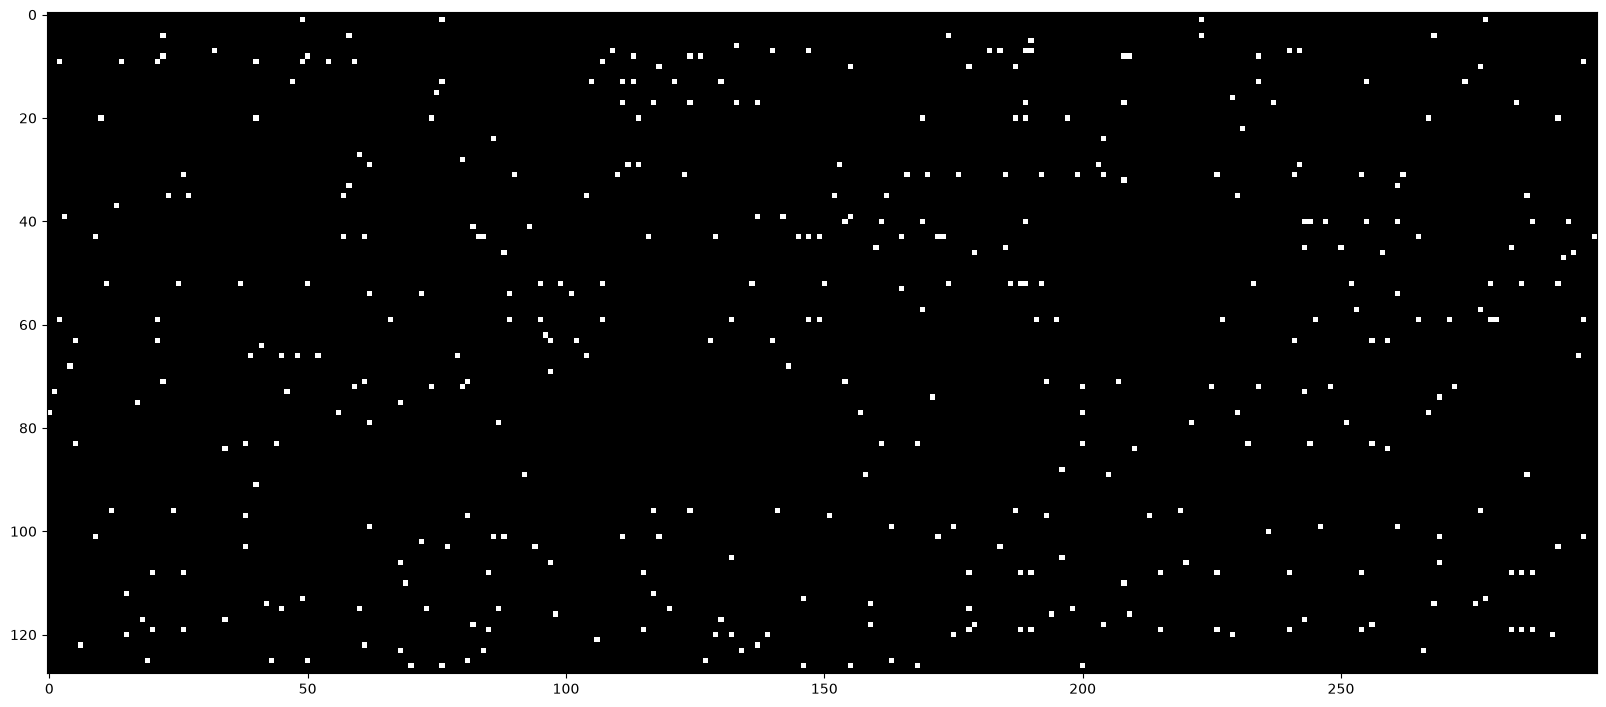

In [30]:
plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap="grey", interpolation="nearest");

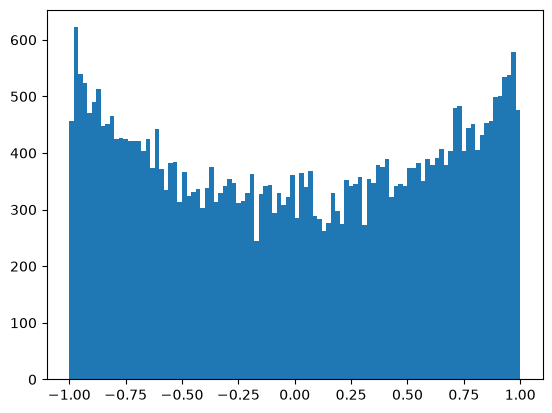

In [31]:
plt.hist(h.view(-1).tolist(), bins=100);

### 4.2 Full Training with BatchNorm (100,000 Steps)
Training the model for 100,000 steps with dynamic batch normalization, updating both model parameters and running statistics.


In [32]:
emb_dim = 10
vocab_size = 27
hidden_size = 300


C = torch.randn(vocab_size, emb_dim)

W1 = torch.randn(hidden_size, block_size * emb_dim) # We don't need to scale W1 anymore
# b1 = torch.zeros(hidden_size) # We don't need b1 because we are using BatchNorm here (It would have just get cancelled)
W2 = torch.randn(vocab_size, hidden_size ) * 0.01 # Still helpul to prevent the initial hockey stick loss
b2 = torch.zeros(vocab_size)

bngain = torch.ones(1, hidden_size)
bnbias = torch.zeros(1, hidden_size)

params = [C, W1, W2, b2, bngain, bnbias]

bnmean_running = torch.zeros((1, hidden_size))
bnstd_running = torch.ones((1, hidden_size))

for p in params:
    p.requires_grad = True

In [33]:
steps = 100_000
batch_size = 128
N = len(Xtr)
lossi = []

for i in range(steps):
    # Batching
    ix = torch.randint(0, N, (batch_size,))
    X_b = Xtr[ix]
    y_b = ytr[ix]

    # Forward Pass
    X_emb = C[X_b].reshape(-1, emb_dim * block_size)
    h_preact = X_emb @ W1.T

    # BatchNorm
    bnmeani = h_preact.mean(dim=0, keepdim=True)
    bnstdi = h_preact.std(dim=0, keepdim=True)

    h_norm = bngain * ((h_preact - bnmeani) / bnstdi) + bnbias

    with torch.no_grad():
        bnmean_running = 0.99 * bnmean_running + 0.01 * bnmeani
        bnstd_running = 0.99 * bnstd_running + 0.01 * bnstdi

    h = torch.tanh(h_norm)
    logits = h @ W2.T + b2

    loss = F.cross_entropy(logits, y_b)

    # Backward pass
    for p in params:
        p.grad = None # Zero grad

    loss.backward()

    lr = 0.1 if i < 60_000 else 0.01

    for p in params:
        p.data += -lr * p.grad

    lossi.append(loss.item())

    if i % 1000 == 0:
        print(f"step: {i:5d} | Loss: {loss.item()}")


step:     0 | Loss: 3.2901172637939453
step:  1000 | Loss: 2.5275514125823975
step:  2000 | Loss: 2.204925298690796
step:  3000 | Loss: 2.23907470703125
step:  4000 | Loss: 2.081482172012329
step:  5000 | Loss: 2.439988851547241
step:  6000 | Loss: 2.156471014022827
step:  7000 | Loss: 2.0865440368652344
step:  8000 | Loss: 2.173872470855713
step:  9000 | Loss: 2.074993371963501
step: 10000 | Loss: 2.0165295600891113
step: 11000 | Loss: 2.279003381729126
step: 12000 | Loss: 2.2898483276367188
step: 13000 | Loss: 2.1051886081695557
step: 14000 | Loss: 2.1967597007751465
step: 15000 | Loss: 2.375575304031372
step: 16000 | Loss: 2.1322999000549316
step: 17000 | Loss: 2.1834046840667725
step: 18000 | Loss: 2.250770330429077
step: 19000 | Loss: 1.8723522424697876
step: 20000 | Loss: 2.131442070007324
step: 21000 | Loss: 2.176028251647949
step: 22000 | Loss: 2.103149890899658
step: 23000 | Loss: 2.1979706287384033
step: 24000 | Loss: 1.9600605964660645
step: 25000 | Loss: 2.1814463138580322


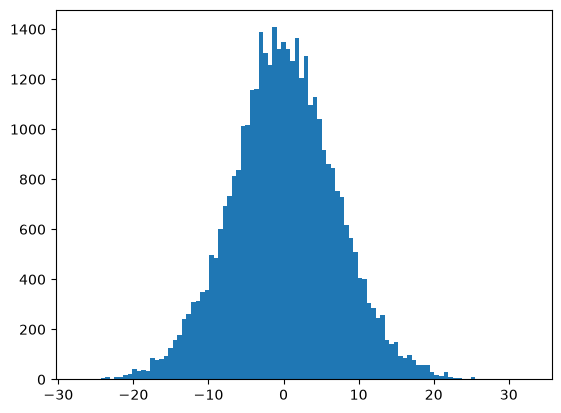

In [34]:
# Distribution of h_preact
plt.hist(h_preact.view(-1).tolist(), bins=100);

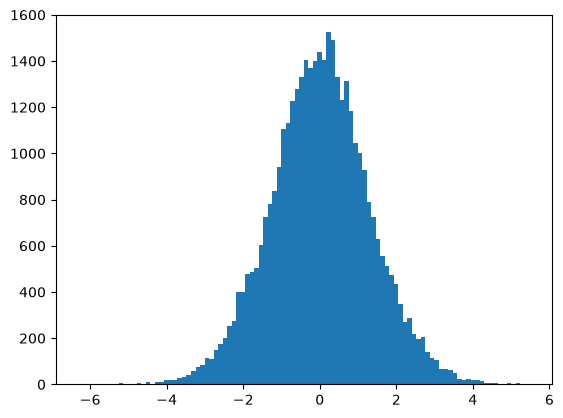

In [35]:
# After BatchNorm
plt.hist(h_norm.view(-1).tolist(), bins=100);

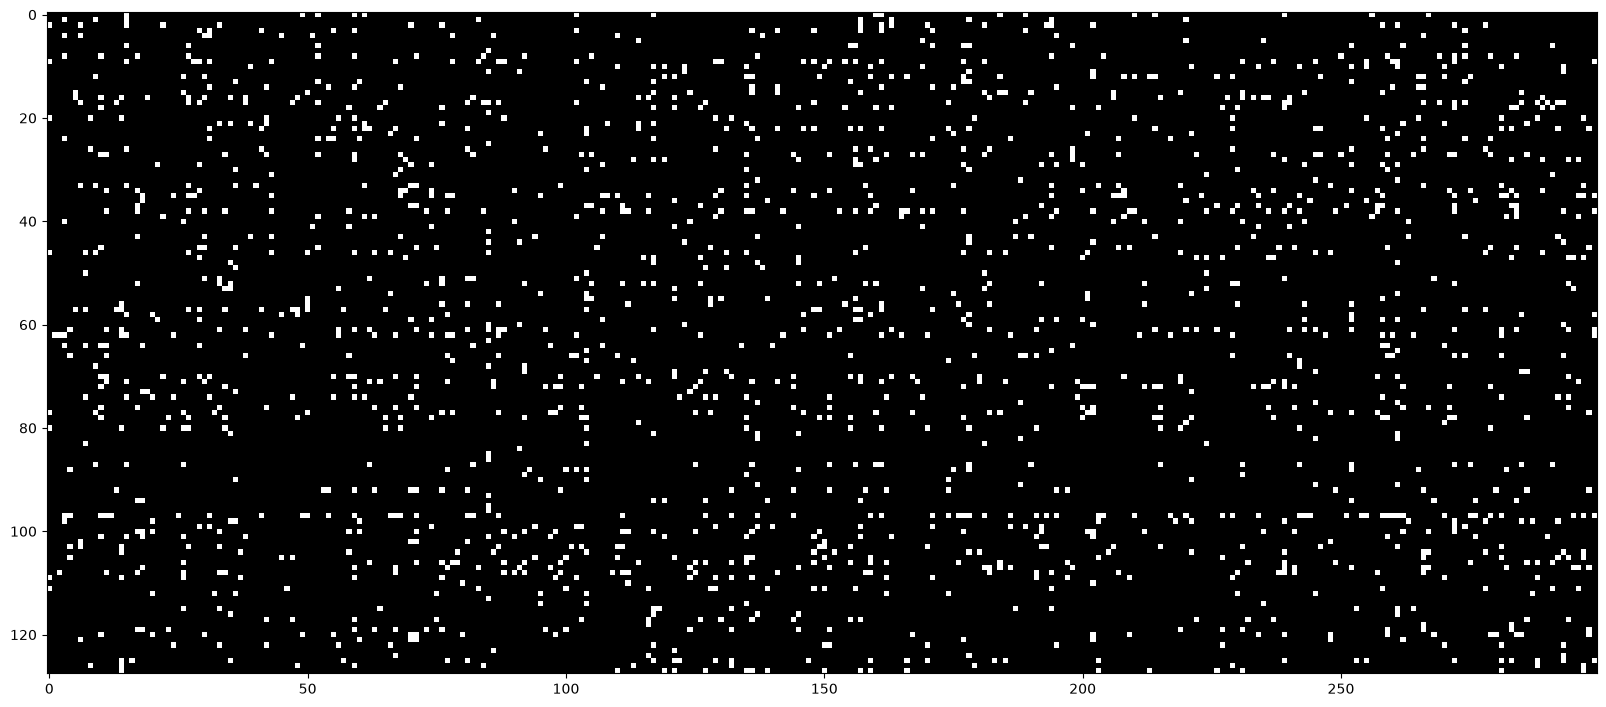

In [36]:
plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap="grey", interpolation="nearest");

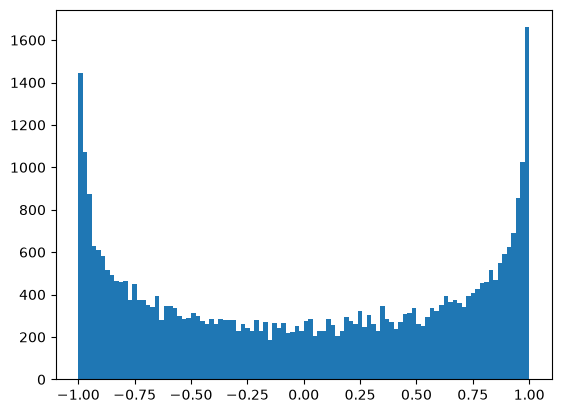

In [37]:
plt.hist(h.view(-1).tolist(), bins=100);

#### Post-Training Observations (BatchNorm Model)
- **Active Linear Representations:** Over $95\%$ of the $\tanh$ activations sit inside the active range $(-0.8, +0.8)$.
- **No Dead Neurons:** The 2D density map is overwhelmingly black with zero dead columns.
- **Controlled Saturation:** The small peaks at $\pm 1.0$ (only $\approx 1,800$, down from $16,000$ in the unscaled run) reflect intentional, learned feature specialization via `bngain` and `bnbias`.


## 5. Model Evaluation & Inference

At inference time, we switch from batch statistics to our frozen running statistics (`bnmean_running`, `bnstd_running`). This ensures deterministic predictions and allows the model to process single inputs ($N = 1$) without division-by-zero errors.


In [38]:
# Val loss
with torch.no_grad():
    X_emb = C[Xdev].reshape(-1, emb_dim * block_size)
    h_preact = X_emb @ W1.T
    h_norm = bngain * ((h_preact - bnmean_running) / bnstd_running) + bnbias
    h = torch.tanh(h_norm)
    logits = h @ W2.T + b2
    loss = F.cross_entropy(logits, ydev)
    print(loss.item())

2.095848798751831


In [39]:
# Test Loss
with torch.no_grad():
    X_emb = C[Xtr].reshape(-1, emb_dim * block_size)
    h_preact = X_emb @ W1.T
    h_norm = bngain * ((h_preact - bnmean_running) / bnstd_running) + bnbias
    h = torch.tanh(h_norm)
    logits = h @ W2.T + b2
    loss = F.cross_entropy(logits, ytr)
    print(loss.item())

2.0449349880218506


In [46]:
for _ in range(15):
    out = []
    context = [0] * block_size
    
    while True:
        h_preact =  C[torch.tensor([context])].view(1, -1) @ W1.T
        h_norm = bngain * ((h_preact - bnmean_running) / bnstd_running) + bnbias
        h = torch.tanh(h_norm)
        logits = h @ W2.T + b2
        counts = logits.exp()
        probs = counts / counts.sum(1, keepdim=True)
        ix = torch.multinomial(probs, num_samples=1, replacement=True).item()
        if ix == 0:
            break
        out.append(itos[ix])

        context = context[1:] + [ix]
    print(''.join(out))

romiah
hadanisra
debaiani
she
zildiga
denlez
lin
sahnie
zeiout
alicah
jahna
kandix
breel
azir
kanif
